# Linear RSD and the group–velocity dipole: what redshift space actually changes

The companion notebook `linear_theory_parameter_scans.ipynb` established how $b$, $f$,
$\sigma_8$ and $\Omega_m$ enter the **real-space** linear $\zeta_1$. This one asks a
narrower question with a sharper answer:

> In the distant-observer limit, what does linear redshift-space distortion do to the
> group-centred density–velocity correlation?

**It does exactly two things, and nothing else:**

$$\zeta_1^{s}(r) = -\frac{aH f\,(b + \tfrac{3}{5}f)}{6\pi^2}\int\! dk\; k\,P_{\rm lin}(k)\, j_1(kr)$$

$$\zeta_3^{s}(r) = +\frac{aH f\,(\tfrac{2}{5}f)}{14\pi^2}\int\! dk\; k\,P_{\rm lin}(k)\, j_3(kr)$$

$$\zeta_0^{s} = \zeta_2^{s} = 0 \quad\text{(DOL)}$$

Real space is the $b + \tfrac{3}{5}f \to b$, $\zeta_3 \to 0$ limit. Written above in the
**group-centred** sign convention ($r = s_V - s_T$, $\mu = \hat n_T\cdot\hat r$), where the
dipole is negative for infall — hard rule 2.

## Where this comes from

**1. The only linear RSD effect is on the density leg.** Redshift space displaces a tracer
along its own line of sight by its own radial velocity. For a *number density*, that
displacement is a coordinate remapping with a Jacobian, and to linear order

$$\delta_T \;\to\; \delta_T - \nabla\!\cdot(u\,\hat n) \qquad\Longrightarrow\qquad
\delta_T(\mathbf k) \to (b + f\mu_k^2)\,\delta_m(\mathbf k)$$

the Kaiser factor.

**2. The velocity leg is undistorted.** $u$ is a velocity, not a number density. There is
no Jacobian and no divergence term: moving the object does not change how fast it is
moving. Velocities are also unbiased — dark matter and haloes share one large-scale
velocity field — so the velocity leg carries no $b$ at all.

**3. Displacing the velocity object changes *where* $u$ is evaluated, not its value.**
The correction is $\langle \delta_T\,(u\,\hat n\cdot\nabla)u\rangle$: three fields, hence
second order, hence absent from linear theory. This is the theory statement of the
invariant `dvcorr.redshift_space` already asserts numerically — $\hat n$ is unchanged by a
purely radial displacement, so $u_\alpha = \mathbf v_\alpha\cdot\hat n_{V,\alpha}$ is
*identical* between real and redshift space (verified there to $8.5\times10^{-14}$). What
changes between the two runs is **shell composition only**.

**4. $\mu_k^3$ is the entire source of the $3/5$ and of the octupole.** The cross-spectrum
picks up the Kaiser factor on one leg and $\mu_k$ from the velocity projection, so the
angular structure to expand is $(b + f\mu_k^2)\mu_k = b\,\mu_k + f\,\mu_k^3$. Since

$$\mu_k^3 = \tfrac{3}{5}L_1(\mu_k) + \tfrac{2}{5}L_3(\mu_k),$$

the $f\mu_k^3$ term puts $\tfrac{3}{5}f$ into the **dipole** and $\tfrac{2}{5}f$ into a new
**octupole**. That single Legendre identity is the whole of this notebook's physics.

**5. The $f\mu_k^2$ term is unbiased.** It multiplies the same unbiased velocity leg, so
the RSD correction scales as $f^2$, not $bf$. That is why $\zeta_3^s$ carries **no $b$
whatsoever** — it is pure $f^2\sigma_8^2$.

## Sign convention used for plotting

The production module `dvcorr.pipeline.galaxy_bias.zeta_one_linear_prediction` returns the
**velocity-centred** multipole, related to the group-centred one above by
`conventions.nusser_multipole_sign(ell)` $= (-1)^\ell$. This notebook **plots the
velocity-centred quantity**, to stay consistent with the real-space notebook next to it and
with `NormalizedDipole.zeta_hat`, which is what a measurement would be overlaid against.
Both signs are asserted explicitly below. Note the consequence: $\zeta_1^s > 0$ and
$\zeta_3^s < 0$ in the plotted convention, and the reverse group-centred.

## 1. Setup and the fiducial model

MDPL2: $\Omega_m = 0.307$, $h = 0.678$, $\sigma_8 = 0.823$, $n_s = 0.96$, at the snapshot
redshift $z = 0$. Everything is read from `CosmologyConfig` rather than retyped, and
$aH = H(z)/h$ in km/s per $h^{-1}$Mpc is asserted to be **exactly 100** at $z=0$ — the
one-line check that the unit conversion in `zeta_one_linear_prediction` is the right way
up (getting it upside down costs a factor $h^2$, flat in $r$, invisible on a plot).

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

from dvcorr import conventions
from dvcorr.config import CosmologyConfig
from dvcorr.pipeline import galaxy_bias as gb

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
FIG_DPI = 150

COSMO_FID = CosmologyConfig()
Z = gb.SNAPSHOT_REDSHIFT

B_FID = 1.0
S8_FID = COSMO_FID.sigma8
OM_FID = COSMO_FID.Om0
F_FID = (OM_FID / (OM_FID + COSMO_FID.Ode0)) ** COSMO_FID.growth_index

# aH in km/s per h^-1 Mpc: H(z) / h. At z = 0 this must be EXACTLY 100.
scale_factor = 1.0 / (1.0 + Z)
hubble_z = COSMO_FID.H0 * np.sqrt(OM_FID * (1.0 + Z) ** 3 + COSMO_FID.Ode0)
aH = scale_factor * hubble_z / COSMO_FID.h
assert Z == 0.0, f"snapshot redshift is {Z}, not 0 -- aH = 100 no longer holds"
assert abs(aH - 100.0) < 1e-12, f"aH = {aH!r}, expected exactly 100"

print(f"snapshot redshift z      = {Z}")
print(f"Omega_m                  = {OM_FID}")
print(f"h                        = {COSMO_FID.h}   (H0 = {COSMO_FID.H0} km/s/Mpc)")
print(f"sigma8                   = {S8_FID}")
print(f"n_s                      = {COSMO_FID.ns}")
print(f"f_fid = Om^{COSMO_FID.growth_index}         = {F_FID:.6f}")
print(f"3 f_fid / 5              = {3.0 * F_FID / 5.0:.6f}")
print(f"b_fid                    = {B_FID}")
print(f"aH [km/s per h^-1 Mpc]   = {aH!r}  <- exactly 100")
print()
print(f"Kaiser dipole factor  b + 3f/5 = {B_FID + 3.0 * F_FID / 5.0:.6f}")
print(f"boost 1 + 3f/(5b)              = {1.0 + 3.0 * F_FID / (5.0 * B_FID):.6f}")

snapshot redshift z      = 0.0
Omega_m                  = 0.307115
h                        = 0.6777   (H0 = 67.77 km/s/Mpc)
sigma8                   = 0.8228
n_s                      = 0.96
f_fid = Om^0.55         = 0.522415
3 f_fid / 5              = 0.313449
b_fid                    = 1.0
aH [km/s per h^-1 Mpc]   = np.float64(100.0)  <- exactly 100

Kaiser dipole factor  b + 3f/5 = 1.313449
boost 1 + 3f/(5b)              = 1.313449


### The radial grid, and where linear theory stops being true

$r \in [1, 150]\,h^{-1}$Mpc, log-spaced, with $20\,h^{-1}$Mpc spliced in so the solid and
dashed segments of every curve share a point. Curves are drawn **solid for
$r \ge 20\,h^{-1}$Mpc and dashed below**.

Two separate caveats apply below that floor, and this notebook needs both:

- *(shared with real space)* linear theory itself fails — the density field is nonlinear.
- *(specific to redshift space)* **redshift-space linear theory degrades faster than
  real-space linear theory does.** Random virial motions inside haloes scatter tracers
  along the line of sight (Fingers of God), which **suppresses** the measured dipole at
  small $r$ — exactly where the Kaiser formula above *raises* it. The dashed region is
  therefore wrong in a *known direction* here, not merely uncertain: linear RSD
  over-predicts. **None of the panels below include FoG damping.**

In [2]:
R_MIN, R_MAX, N_R = 1.0, 150.0, 500
LINEAR_FLOOR = 20.0  # h^-1 Mpc; below this the curve is drawn dashed

r = np.unique(np.concatenate([np.geomspace(R_MIN, R_MAX, N_R), [LINEAR_FLOOR]]))
below = r <= LINEAR_FLOOR
above = r >= LINEAR_FLOOR
print(f"r grid: {r.size} points, {r[0]:.0f} to {r[-1]:.0f} h^-1 Mpc, log-spaced")

# THE single CAMB call behind every panel.
K_FID, PK_FID = gb.linear_power_spectrum(COSMO_FID, Z, nonlinear=False)
print(f"one CAMB solve: k in [{K_FID[0]:.1e}, {K_FID[-1]:.1f}] h/Mpc, {K_FID.size} points")


def _spectrum(sigma8):
    """(k, P) renormalized to `sigma8`, or the fiducial spectrum if None.

    P is linear in A_s and sigma8**2 is linear in P, so rescaling by
    (sigma8 / sigma8_fid)**2 is EXACTLY equivalent to re-running CAMB at the new
    normalization -- which is why the sigma8 scan below does not re-run CAMB.
    """
    if sigma8 is None:
        return K_FID, PK_FID
    return K_FID, PK_FID * (sigma8 / COSMO_FID.sigma8) ** 2


def zeta_one_real(r, b, f, sigma8=None):
    """Real-space zeta_1(r), km/s, shape (B,), velocity-centred (positive for infall)."""
    return gb.zeta_one_linear_prediction(
        r, b=b, cosmology=COSMO_FID, z=Z, f=f, power_spectrum=_spectrum(sigma8)
    )


def zeta_one_rsd(r, b, f, sigma8=None):
    """Redshift-space zeta_1^s(r), km/s, shape (B,), velocity-centred.

    The Kaiser factor enters EXACTLY where b does -- b -> b + 3f/5 -- so this is the
    production real-space function called with a shifted bias, not a reimplementation.
    Everything downstream of that substitution (the k-integral, the FFTLog call, the aH
    conversion, the group -> velocity sign flip) is the library's, untouched.
    """
    return zeta_one_real(r, b=b + 3.0 * f / 5.0, f=f, sigma8=sigma8)


def zeta_three_rsd(r, b=None, f=None, sigma8=None):
    """Redshift-space zeta_3^s(r), km/s, shape (B,), velocity-centred.

    Group-centred:  +(aH f (2f/5) / (14 pi^2)) * S_3(r).  `b` is accepted and IGNORED --
    the octupole is sourced entirely by the unbiased f*mu_k^2 term, so it is pure
    f^2 sigma_8^2 with no bias dependence at all. The argument exists so this function
    is call-compatible with the two above inside the shared scan helper.

    The 2/5 and the 14 are the Legendre identity mu_k^3 = (3/5) L_1 + (2/5) L_3 and the
    ell = 3 normalization (2*ell + 1 = 7, halved by Convention B's 1/2 integral); they are
    part of the derivation and stay inline, per hard rule 4's pure-mathematics exemption.
    """
    k, pk = _spectrum(sigma8)
    s_three = gb.multipole_shape_integral(r, k, pk, ell=3)
    xi_tu_three = +(aH * f * (2.0 * f / 5.0) / (14.0 * np.pi**2)) * s_three
    return conventions.nusser_multipole_sign(3) * xi_tu_three


ZETA1_REAL_FID = zeta_one_real(r, B_FID, F_FID, S8_FID)
ZETA1_RSD_FID = zeta_one_rsd(r, B_FID, F_FID, S8_FID)
ZETA3_RSD_FID = zeta_three_rsd(r, B_FID, F_FID, S8_FID)

print()
print(f"{'r':>5}  {'zeta_1 real':>12}  {'zeta_1^s':>12}  {'zeta_3^s':>12}   [km/s]")
for r_i in (20.0, 50.0, 100.0):
    j = int(np.argmin(np.abs(r - r_i)))
    print(f"{r[j]:5.1f}  {ZETA1_REAL_FID[j]:12.4f}  {ZETA1_RSD_FID[j]:12.4f}  "
          f"{ZETA3_RSD_FID[j]:12.4f}")

r grid: 501 points, 1 to 150 h^-1 Mpc, log-spaced


one CAMB solve: k in [1.0e-05, 50.0] h/Mpc, 2048 points

    r   zeta_1 real      zeta_1^s      zeta_3^s   [km/s]
 20.0       26.5942       34.9301       -1.1136
 50.2       10.5284       13.8285       -0.6808
100.4        3.6549        4.8006       -0.3211


## 2. Required check 1 — validate the $j_3$ FFTLog normalization **independently**

This is new and is **not** covered by whatever was validated for $j_1$. mcfit returns
$i^\ell \times$ (the real integral), so the $\mathrm{Im}(\cdot)$ extraction that is correct
for $\ell=1$ **silently negates** the result at $\ell=3$ (since $i^3 = -i$). Per-order
conventions must not be assumed to carry over — a sign error in the octupole has no other
symptom.

`gb.multipole_shape_integral` therefore uses the $\ell$-general
$2\pi^2\,\mathrm{Re}(\,\cdot\,/\,i^\ell)$. Two independent validations, both **before** any
octupole is plotted:

**(a) closed form.** For $P(k) = k^n$,
$$\int_0^\infty\! dk\;k^{\,n+1} j_\ell(kr) = r^{-s}\,2^{\,s-2}\sqrt\pi\,
\frac{\Gamma(\tfrac{\ell+s}{2})}{\Gamma(\tfrac{\ell-s+3}{2})},\qquad s = n+2.$$
At $n=-1$ this gives $S_1 = 1/r$ and $S_3 = \tfrac{2}{3}\,/\,r$ — different numbers, so the
check is genuinely order-sensitive and not satisfied by an accidental $\ell=1$ answer.

**(b) brute quadrature** against the real CAMB $P_{\rm lin}$ at $r = 5, 30, 80\,h^{-1}$Mpc.

*(Note: the real-space notebook's leg (a) silently returned `nan`, because its $r$ grid
included $r=0$ and $S_{\rm exact}\propto r^{-(n+2)}$ divides by zero there. This grid starts
at $r=1$, so the check actually runs here.)*

In [3]:
from scipy.interpolate import CubicSpline
from scipy.special import gamma as gamma_fn
from scipy.special import spherical_jn

# --- 1a. power law, closed form, per order ---------------------------------
POWER_LAW_INDEX = -1.0
k_pow = np.geomspace(1e-6, 1e4, 4096)
n = POWER_LAW_INDEX
s_pow = n + 2.0

print(f"1a. P(k) = k^{n:.0f}, closed form per order:\n")
print(f"    {'ell':>4}  {'S*r (FFTLog)':>14}  {'S*r (exact)':>13}  {'max frac dev':>13}")
for ell in (1, 3):
    S_fftlog = gb.multipole_shape_integral(r, k_pow, k_pow**n, ell=ell)
    S_exact = (
        r ** (-s_pow) * 2.0 ** (s_pow - 2.0) * np.sqrt(np.pi)
        * gamma_fn((ell + s_pow) / 2.0) / gamma_fn((ell - s_pow + 3.0) / 2.0)
    )
    dev = np.abs(S_fftlog / S_exact - 1.0)
    print(f"    {ell:>4}  {S_fftlog[0]*r[0]:14.6f}  {S_exact[0]*r[0]:13.6f}  {dev.max():13.3e}")
    assert dev.max() < 1e-3, f"ell={ell} closed-form check failed at {dev.max():.3e}"

print("\n    S_1 = 1/r and S_3 = (2/3)/r are DIFFERENT closed forms, so this test cannot")
print("    be passed by an ell=1 answer wearing an ell=3 label. A phase error would show")
print("    as a sign flip (frac dev = -2), not as 1e-4 of FFTLog edge ringing.")

# --- 1b. brute quadrature on the real CAMB P_lin ---------------------------
log_pk = CubicSpline(np.log(K_FID), np.log(PK_FID))

N_QUAD_LOG, N_QUAD_LIN, QUAD_SPLIT = 200_000, 1_000_000, 0.1


def quadrature_shape_integral(r_values, ell, k_min=None, k_max=None):
    """Int dk k P_lin(k) j_ell(k r) by dense trapezoid, shape (len(r_values),).

    Log-spaced below QUAD_SPLIT where the integrand is smooth and spans decades, linear
    above it where j_ell(kr) oscillates and uniform resolution is what matters. A HARD
    truncation, unlike slicing the FFTLog input: mcfit's `extrap=True` power-law extends
    the spectrum past its endpoints, so only quadrature can answer a k-range question.
    """
    k_min = K_FID[0] if k_min is None else k_min
    k_max = K_FID[-1] if k_max is None else k_max
    k_lo = np.geomspace(k_min, min(QUAD_SPLIT, k_max), N_QUAD_LOG)
    k_hi = np.linspace(min(QUAD_SPLIT, k_max), k_max, N_QUAD_LIN)
    k_q = np.unique(np.concatenate([k_lo, k_hi]))
    integrand_pk = k_q * np.exp(log_pk(np.log(k_q)))
    out = np.empty(np.size(r_values))
    for i, r_i in enumerate(np.atleast_1d(r_values)):
        out[i] = np.trapezoid(integrand_pk * spherical_jn(ell, k_q * r_i), k_q)
    return out


R_QUAD_CHECK = np.array([5.0, 30.0, 80.0])
print("\n1b. FFTLog vs brute quadrature on the CAMB P_lin:\n")
print(f"    {'ell':>4}  {'r':>5}  {'quadrature':>13}  {'FFTLog':>13}  {'frac dev':>11}")
worst_quad = {}
for ell in (1, 3):
    S_quad = quadrature_shape_integral(R_QUAD_CHECK, ell=ell)
    S_fft = gb.multipole_shape_integral(R_QUAD_CHECK, K_FID, PK_FID, ell=ell)
    for r_i, q_i, f_i in zip(R_QUAD_CHECK, S_quad, S_fft):
        print(f"    {ell:>4}  {r_i:5.0f}  {q_i:13.6f}  {f_i:13.6f}  {f_i/q_i - 1.0:+11.3e}")
    worst_quad[ell] = np.max(np.abs(S_fft / S_quad - 1.0))
    assert worst_quad[ell] < 1e-3, f"ell={ell} quadrature check failed"

print(f"\n    max |frac dev|:  ell=1 {worst_quad[1]:.3e}   ell=3 {worst_quad[3]:.3e}")
print("    -> the mcfit phase convention is correct AT BOTH ORDERS. Octupole cleared.")

1a. P(k) = k^-1, closed form per order:

     ell    S*r (FFTLog)    S*r (exact)   max frac dev
       1        1.000000       1.000000      2.603e-12
       3        0.666667       0.666667      2.603e-12

    S_1 = 1/r and S_3 = (2/3)/r are DIFFERENT closed forms, so this test cannot
    be passed by an ell=1 answer wearing an ell=3 label. A phase error would show
    as a sign flip (frac dev = -2), not as 1e-4 of FFTLog edge ringing.

1b. FFTLog vs brute quadrature on the CAMB P_lin:

     ell      r     quadrature         FFTLog     frac dev


       1      5      53.564246      53.564130   -2.155e-06
       1     30      21.393315      21.393311   -1.958e-07
       1     80       5.937988       5.937989   +1.223e-07


       3      5      14.679253      14.679368   +7.830e-06
       3     30      12.008610      12.008613   +2.912e-07
       3     80       5.543417       5.543416   -2.882e-08

    max |frac dev|:  ell=1 2.155e-06   ell=3 7.830e-06
    -> the mcfit phase convention is correct AT BOTH ORDERS. Octupole cleared.


## 3. Required check 2 — the real-space limit

Setting $f \to 0$ **in the Kaiser factor only** — i.e. evaluating with
$b + \tfrac{3}{5}f \to b$ while holding the overall $f$ prefactor fixed — must reproduce
the real-space $\zeta_1$ to float tolerance, and $\zeta_3^s$ must vanish. This isolates the
Kaiser substitution from the growth-rate prefactor: they are two different appearances of
$f$ and only one of them is the RSD effect.

In [4]:
zeta1_limit = zeta_one_real(r, b=B_FID, f=F_FID, sigma8=S8_FID)  # Kaiser factor -> b
dev_limit = np.abs(zeta1_limit / ZETA1_REAL_FID - 1.0).max()

zeta3_limit = zeta_three_rsd(r, b=B_FID, f=0.0, sigma8=S8_FID)   # f -> 0 in the octupole

print(f"zeta_1^s with (b + 3f/5) -> b, f prefactor held:")
print(f"    max fractional deviation from real-space zeta_1 = {dev_limit:.3e}")
print(f"zeta_3^s at f = 0:  max |zeta_3^s| = {np.abs(zeta3_limit).max():.3e} km/s")

assert dev_limit == 0.0 or dev_limit < 1e-14, f"real-space limit failed: {dev_limit:.3e}"
assert np.all(zeta3_limit == 0.0), "zeta_3^s must be identically zero at f = 0"
print("\nPASSED -- the two appearances of f are correctly separated, and the octupole")
print("is sourced by the Kaiser term alone.")

zeta_1^s with (b + 3f/5) -> b, f prefactor held:
    max fractional deviation from real-space zeta_1 = 0.000e+00
zeta_3^s at f = 0:  max |zeta_3^s| = 0.000e+00 km/s

PASSED -- the two appearances of f are correctly separated, and the octupole
is sourced by the Kaiser term alone.


## 4. Required check 6 — sign sanity

$\zeta_1^s$ must have the infall sign at **every** radius for positive $b$, $f$, $\sigma_8$.
Asserted in both conventions, since the plotted (velocity-centred) and frozen
(group-centred) signs are opposite and getting them confused is exactly the failure
hard rule 2 exists to catch.

Note $\zeta_3^s$ has the **opposite** sign to $\zeta_1^s$ in either convention: group-centred
$\zeta_1 < 0 < \zeta_3$. That is not an error — the two multipoles carry opposite signs in
the expansion $(b + f\mu_k^2)\mu_k$, and the $(-1)^\ell$ centring flip is the same factor
$-1$ for both odd orders, so it cannot reconcile them.

In [5]:
xi_Tu_one = conventions.nusser_multipole_sign(1) * ZETA1_RSD_FID     # group-centred
xi_Tu_three = conventions.nusser_multipole_sign(3) * ZETA3_RSD_FID   # group-centred

assert np.all(np.isfinite(ZETA1_RSD_FID)) and np.all(np.isfinite(ZETA3_RSD_FID))
assert np.all(ZETA1_RSD_FID > 0.0), "zeta_1^s must be POSITIVE for infall (velocity-centred)"
assert np.all(xi_Tu_one < 0.0), "xi_Tu,1^s must be NEGATIVE for infall (group-centred)"
assert np.sign(xi_Tu_one[0]) == conventions.INFALL_DIPOLE_SIGN

print(f"zeta_1^s  (velocity-centred) > 0 at all {r.size} radii: "
      f"min = {ZETA1_RSD_FID.min():.4f} km/s")
print(f"xi_Tu,1^s (group-centred)    < 0 at all {r.size} radii: "
      f"max = {xi_Tu_one.max():.4f} km/s")
print(f"conventions.INFALL_DIPOLE_SIGN = {conventions.INFALL_DIPOLE_SIGN}  -> consistent")
print()
print(f"zeta_3^s  (velocity-centred) sign: min {ZETA3_RSD_FID.min():+.4f}, "
      f"max {ZETA3_RSD_FID.max():+.4f} km/s")
print(f"xi_Tu,3^s (group-centred)    sign: min {xi_Tu_three.min():+.4f}, "
      f"max {xi_Tu_three.max():+.4f} km/s")
assert np.all(xi_Tu_three > 0.0), "xi_Tu,3^s must be POSITIVE (opposite the dipole)"
print("-> octupole carries the OPPOSITE sign to the dipole, in both conventions.")

zeta_1^s  (velocity-centred) > 0 at all 501 radii: min = 2.2389 km/s
xi_Tu,1^s (group-centred)    < 0 at all 501 radii: max = -2.2389 km/s
conventions.INFALL_DIPOLE_SIGN = -1  -> consistent

zeta_3^s  (velocity-centred) sign: min -1.2364, max -0.1959 km/s
xi_Tu,3^s (group-centred)    sign: min +0.1959, max +1.2364 km/s
-> octupole carries the OPPOSITE sign to the dipole, in both conventions.


## 5. Required checks 3 & 4 — $k$-range sensitivity

**$k_{\rm min}$ (check 3).** Truncating at the MDPL2 box fundamental mode
$k_{\rm box} = 2\pi/1000\;h\,{\rm Mpc}^{-1}$ asks whether the box contains the modes the
theory integrates over. $\zeta_3^s$ is reported **separately**: $j_3$ weights large scales
differently from $j_1$ (it rises as $x^3$ rather than $x$, so it suppresses low $k$ *more*),
and the box-mode sensitivity is not assumed to be the same.

**$k_{\rm max}$ (check 4).** $\Lambda$CDM $P(k)$ falls only as $k^{n_s-4}\ln^2 k$, so
$\sigma^2 = (1/2\pi^2)\int k^2 P\,dk$ — which sets the $r\to0$ slope — converges slowly.
Truncation at $k_{\rm max} \in \{10, 10^2, 10^3\}$, read at $r = 1, 5, 20\,h^{-1}$Mpc.

Both use **brute quadrature**, which truncates hard; slicing the FFTLog input would not,
because mcfit's `extrap=True` power-law extends the spectrum past its endpoints.

In [6]:
K_BOX = 2.0 * np.pi / conventions.BOX_SIZE
R_KMIN_CHECK = np.array([20.0, 50.0, 100.0])

print(f"MDPL2 box = {conventions.BOX_SIZE:.0f} h^-1 Mpc  ->  k_box = 2 pi / L = "
      f"{K_BOX:.5f} h/Mpc   (theory normally starts at {K_FID[0]:.1e})\n")
print(f"{'ell':>4}  {'r':>5}  {'full':>12}  {'k >= k_box':>12}  {'frac change':>12}")
kmin_worst = {}
for ell in (1, 3):
    S_full = quadrature_shape_integral(R_KMIN_CHECK, ell=ell)
    S_trunc = quadrature_shape_integral(R_KMIN_CHECK, ell=ell, k_min=K_BOX)
    for r_i, a_i, b_i in zip(R_KMIN_CHECK, S_full, S_trunc):
        print(f"{ell:>4}  {r_i:5.0f}  {a_i:12.5f}  {b_i:12.5f}  {b_i/a_i - 1.0:+11.4%}")
    kmin_worst[ell] = np.max(np.abs(S_trunc / S_full - 1.0))

print(f"\nlargest k_min effect:  zeta_1^s {kmin_worst[1]:.4%}   zeta_3^s {kmin_worst[3]:.4%}")
print("The dipole and octupole are affected by the box cut-off to DIFFERENT degrees --")
print("j_3 ~ x^3 at small argument suppresses large-scale power harder than j_1 ~ x does,")
print("so the octupole is the LESS box-sensitive of the two, not the more.")

MDPL2 box = 1000 h^-1 Mpc  ->  k_box = 2 pi / L = 0.00628 h/Mpc   (theory normally starts at 1.0e-05)

 ell      r          full    k >= k_box   frac change


   1     20      30.14547      30.13712     -0.0277%
   1     50      11.99861      11.97786     -0.1729%
   1    100       4.16103       4.12033     -0.9782%


   3     20      14.09519      14.09519     -0.0000%
   3     50       8.64464       8.64460     -0.0004%
   3    100       4.09211       4.09181     -0.0074%

largest k_min effect:  zeta_1^s 0.9782%   zeta_3^s 0.0074%
The dipole and octupole are affected by the box cut-off to DIFFERENT degrees --
j_3 ~ x^3 at small argument suppresses large-scale power harder than j_1 ~ x does,
so the octupole is the LESS box-sensitive of the two, not the more.


In [7]:
R_KMAX_CHECK = np.array([1.0, 5.0, 20.0])
KMAX_SCAN = (1e1, 1e2, 1e3)

# The CAMB spectrum stops at CAMB_K_MAX; beyond it the log-log CubicSpline extrapolates,
# which for LCDM's smooth k^(ns-4) ln^2 k tail is a controlled continuation rather than a
# guess. Stated because 1e3 is 20x past where CAMB was actually solved.
print(f"CAMB solved to k = {K_FID[-1]:.0f} h/Mpc; beyond that the log-log spline continues")
print(f"the k^(ns-4) ln^2 k tail. Reference below is the k_max = {KMAX_SCAN[-1]:.0e} column.\n")

S_ref = quadrature_shape_integral(R_KMAX_CHECK, ell=1, k_max=KMAX_SCAN[-1])
print(f"zeta_1^s, fractional change vs k_max = {KMAX_SCAN[-1]:.0e}:\n")
header = "    " + f"{'r':>5}" + "".join(f"{f'k_max={km:.0e}':>16}" for km in KMAX_SCAN)
print(header)
rows = [quadrature_shape_integral(R_KMAX_CHECK, ell=1, k_max=km) for km in KMAX_SCAN]
for i, r_i in enumerate(R_KMAX_CHECK):
    cells = "".join(f"{rows[j][i]/S_ref[i] - 1.0:+15.4%} " for j in range(len(KMAX_SCAN)))
    print(f"    {r_i:5.0f}" + cells)

print("\nThe r-dependence is the whole story, and the effect is SMALL over the plotted")
print("range: truncating at k = 10 h/Mpc costs 0.18% at r = 1 and 0.001% at r = 20, a")
print("factor ~150 between them. j_1(kr) oscillates the high-k contribution away, and it")
print("does so sooner the larger r is -- so k_max convergence is a non-issue for every")
print("panel in this notebook, all of which live at r >= 1 h^-1 Mpc.")
print("\nsigma^2 itself is nowhere near converged at k_max = 50 (it roughly doubles from")
print("k_max = 10 to 50). That matters only where the r -> 0 asymptote is approached,")
print("i.e. r << 1/k_max, which is check 5's territory and two decades below anything")
print("plotted here. The two statements are consistent: the integral is k_max-sensitive,")
print("the integral WEIGHTED BY j_1(kr) at r >= 1 h^-1 Mpc is not.")

CAMB solved to k = 50 h/Mpc; beyond that the log-log spline continues
the k^(ns-4) ln^2 k tail. Reference below is the k_max = 1e+03 column.



zeta_1^s, fractional change vs k_max = 1e+03:

        r     k_max=1e+01     k_max=1e+02     k_max=1e+03


        1       +0.1822%        +0.0005%        +0.0000% 
        5       +0.0049%        +0.0001%        +0.0000% 
       20       +0.0012%        -0.0004%        +0.0000% 

The r-dependence is the whole story, and the effect is SMALL over the plotted
range: truncating at k = 10 h/Mpc costs 0.18% at r = 1 and 0.001% at r = 20, a
factor ~150 between them. j_1(kr) oscillates the high-k contribution away, and it
does so sooner the larger r is -- so k_max convergence is a non-issue for every
panel in this notebook, all of which live at r >= 1 h^-1 Mpc.

sigma^2 itself is nowhere near converged at k_max = 50 (it roughly doubles from
k_max = 10 to 50). That matters only where the r -> 0 asymptote is approached,
i.e. r << 1/k_max, which is check 5's territory and two decades below anything
plotted here. The two statements are consistent: the integral is k_max-sensitive,
the integral WEIGHTED BY j_1(kr) at r >= 1 h^-1 Mpc is not.


## 6. Required check 5 — the $r\to0$ slope

As $r\to0$, $j_1(x)\to x/3$, so

$$\zeta_1^s(r) \;\longrightarrow\; -\frac{(b+\tfrac35 f)\,aH\,f\,\sigma^2}{9}\,r,
\qquad \sigma^2 = \frac{1}{2\pi^2}\!\int\! k^2 P(k)\,dk$$

(group-centred; positive in the plotted convention). $\sigma^2$ is computed by **direct
quadrature over the CAMB spectrum — no Bessel transform** — so the comparison is genuinely
independent of the transform's normalization.

### This check cannot be run on the FFTLog path, and the reason is worth stating

The asymptotic form needs $kr \ll 1$ across the *whole* integral. $\sigma^2$ is dominated by
the highest $k$ in the spectrum (check 4: it is still climbing at $k = 50$), so the asymptote
only sets in for $r \ll 1/k_{\rm max} = 0.02\,h^{-1}$Mpc.

But `gb.THEORY_MIN_RADIUS` $= 1/k_{\rm max}$ is *also* the radius below which the FFTLog
output is being **extrapolated** rather than evaluated — the transform of a spectrum sampled
to $k_{\rm max}$ simply does not carry information below that scale. **The two windows share
a threshold and never overlap.** Measured: the FFTLog sits $+41\%$ above quadrature at
$r = 0.02$, $+5.9\%$ at $0.05$, and only reaches $-0.1\%$ by $r = 0.2\,h^{-1}$Mpc.

So the identity is checked where it can be checked — on **brute quadrature**, which has no
small-$r$ floor — with $\sigma^2$ integrated over the *same* $k$-range, since $\sigma^2$ is a
$k_{\rm max}$-dependent number and comparing two different truncations would prove nothing.
This is not a weaker test: check 1 already validated FFTLog against quadrature at
$r = 5, 30, 80\,h^{-1}$Mpc to $2\times10^{-6}$, so quadrature $\leftrightarrow$ analytic
asymptote here closes the loop end to end.

*(For the range the notebook actually plots, $r \ge 1\,h^{-1}$Mpc, the FFTLog agrees with
quadrature to $2\times10^{-5}$ or better — none of this touches any panel.)*

### $\zeta_3^s \propto r^3$

$j_3(x) \to x^3/105$, so the small-$r$ log-log slope is exactly 3. The same window problem
applies, more severely: $j_3$ needs $kr\ll1$ harder than $j_1$ does. The slope is reported
over $r \in [1, 3]\,h^{-1}$Mpc as specified **and** over the range where the asymptote
actually holds, because the first of those is nowhere near it.

In [8]:
# sigma^2 over EXACTLY the k-range the shape integral uses -- same truncation on both
# sides, since sigma^2 is a k_max-dependent number (check 4).
k_sig = np.geomspace(K_FID[0], K_FID[-1], 2_000_000)
sigma_sq = np.trapezoid(k_sig**2 * np.exp(log_pk(np.log(k_sig))), k_sig) / (2.0 * np.pi**2)
print(f"sigma^2 by direct quadrature over k <= {K_FID[-1]:.0f} h/Mpc, no Bessel transform:")
print(f"    sigma^2 = {sigma_sq:.5f}   (dimensionless density variance; NOT converged in")
print(f"    k_max -- see check 4 -- which is why both sides use the same truncation)\n")

kaiser = B_FID + 3.0 * F_FID / 5.0
slope_predicted = kaiser * aH * F_FID * sigma_sq / 9.0  # km/s per h^-1 Mpc, positive branch
print(f"predicted r -> 0 slope  (b + 3f/5) aH f sigma^2 / 9 = {slope_predicted:.4f} "
      "km/s per h^-1 Mpc\n")

AMPLITUDE_RSD = kaiser * aH * F_FID / (6.0 * np.pi**2) * (S8_FID / COSMO_FID.sigma8) ** 2


def zeta_one_rsd_quadrature(r_values):
    """zeta_1^s by brute quadrature, km/s -- no FFTLog, hence no small-r floor."""
    return AMPLITUDE_RSD * quadrature_shape_integral(r_values, ell=1)


r_small = np.array([1e-5, 1e-4, 1e-3, 1e-2, 2e-2, 1e-1, 1.0])
zeta1_small = zeta_one_rsd_quadrature(r_small)
print(f"    {'r':>9}  {'zeta_1^s / r':>13}  {'frac dev':>12}")
for r_i, z_i in zip(r_small, zeta1_small):
    print(f"    {r_i:9.1e}  {z_i/r_i:13.4f}  {z_i/r_i/slope_predicted - 1.0:+12.5%}")

frac_asymptote = abs(zeta1_small[1] / r_small[1] / slope_predicted - 1.0)
print(f"\nFRACTIONAL AGREEMENT at r = {r_small[1]:.0e} h^-1 Mpc: {frac_asymptote:.2e}")
assert frac_asymptote < 1e-5, f"r -> 0 slope check failed at {frac_asymptote:.3e}"
print("PASSED -- the aH / 6 pi^2 normalization chain reproduces an independently")
print("computed sigma^2 exactly. Combined with check 1 (FFTLog vs quadrature to 2e-6),")
print("the whole path from P_lin(k) to km/s is closed end to end.\n")

# The FFTLog path over the same radii, to show WHY it could not be used here.
print("The same radii through the FFTLog, for contrast "
      f"(gb.THEORY_MIN_RADIUS = {gb.THEORY_MIN_RADIUS:.4f}):\n")
print(f"    {'r':>9}  {'quadrature':>12}  {'FFTLog':>12}  {'dev':>10}")
for r_i in (0.02, 0.05, 0.2, 1.0, 5.0):
    q = quadrature_shape_integral(np.array([r_i]), ell=1)[0]
    fl = gb.multipole_shape_integral(np.array([r_i]), K_FID, PK_FID, ell=1)[0]
    print(f"    {r_i:9.3f}  {q:12.4f}  {fl:12.4f}  {fl/q - 1.0:+9.3%}")
print("\n-> below ~0.2 h^-1 Mpc the transform is extrapolating, and the asymptote lives")
print("   two decades further down. No overlap. Everything the panels plot is r >= 1.")

sigma^2 by direct quadrature over k <= 50 h/Mpc, no Bessel transform:
    sigma^2 = 43.64926   (dimensionless density variance; NOT converged in
    k_max -- see check 4 -- which is why both sides use the same truncation)

predicted r -> 0 slope  (b + 3f/5) aH f sigma^2 / 9 = 332.7845 km/s per h^-1 Mpc



            r   zeta_1^s / r      frac dev
      1.0e-05       332.7845     -0.00000%
      1.0e-04       332.7844     -0.00005%
      1.0e-03       332.7689     -0.00469%
      1.0e-02       331.2312     -0.46676%
      2.0e-02       326.6595     -1.84052%
      1.0e-01       232.2125    -30.22136%
      1.0e+00        56.1652    -83.12264%

FRACTIONAL AGREEMENT at r = 1e-04 h^-1 Mpc: 4.69e-07
PASSED -- the aH / 6 pi^2 normalization chain reproduces an independently
computed sigma^2 exactly. Combined with check 1 (FFTLog vs quadrature to 2e-6),
the whole path from P_lin(k) to km/s is closed end to end.

The same radii through the FFTLog, for contrast (gb.THEORY_MIN_RADIUS = 0.0200):

            r    quadrature        FFTLog         dev


        0.020        5.6383        7.9292   +40.631%


        0.050       12.8628       13.6193    +5.882%
        0.200       27.6191       27.5902    -0.105%


        1.000       48.4719       48.4710    -0.002%
        5.000       53.5642       53.5641    -0.000%

-> below ~0.2 h^-1 Mpc the transform is extrapolating, and the asymptote lives
   two decades further down. No overlap. Everything the panels plot is r >= 1.


In [9]:
# --- zeta_3^s log-log slope: as specified, and where the asymptote actually is ---
AMPLITUDE_THREE = (
    conventions.nusser_multipole_sign(3)
    * aH * F_FID * (2.0 * F_FID / 5.0) / (14.0 * np.pi**2)
    * (S8_FID / COSMO_FID.sigma8) ** 2
)

print("zeta_3^s log-log slope, fitted by brute quadrature (expected 3.0 asymptotically):\n")
print(f"    {'range in r [h^-1 Mpc]':>26}  {'slope':>8}  {'dev from 3':>11}")
slopes = {}
for lo, hi in ((1.0, 3.0), (1e-1, 3e-1), (1e-2, 3e-2), (1e-3, 3e-3), (1e-4, 3e-4)):
    rr = np.geomspace(lo, hi, 25)
    z3 = np.abs(AMPLITUDE_THREE * quadrature_shape_integral(rr, ell=3))
    slopes[(lo, hi)] = float(np.polyfit(np.log(rr), np.log(z3), 1)[0])
    marker = "   <- as specified" if lo == 1.0 else ""
    print(f"    {f'[{lo:.0e}, {hi:.0e}]':>26}  {slopes[(lo, hi)]:8.4f}  "
          f"{slopes[(lo,hi)] - 3.0:+11.4f}{marker}")

specified = slopes[(1.0, 3.0)]
asymptotic = slopes[(1e-4, 3e-4)]
print(f"\nOVER r in [1, 3] h^-1 Mpc THE SLOPE IS {specified:.3f}, NOT 3.0.")
print("That range is nowhere near the asymptotic regime -- j_3 needs kr << 1 across the")
print("whole integral, and at r = 1 the integrand is still collecting power at k ~ 1.")
print(f"The r^3 law is real and exact, it just lives below r ~ 0.03: slope reaches")
print(f"{slopes[(1e-2, 3e-2)]:.3f} by r ~ 0.02 and {asymptotic:.4f} by r ~ 1e-4.")
assert abs(asymptotic - 3.0) < 0.01, f"asymptotic zeta_3 slope is {asymptotic:.4f}, not 3"
print("\nPASSED on the asymptotic range. Reported honestly on the specified one.")

zeta_3^s log-log slope, fitted by brute quadrature (expected 3.0 asymptotically):

         range in r [h^-1 Mpc]     slope   dev from 3


                [1e+00, 3e+00]    0.4060      -2.5940   <- as specified


                [1e-01, 3e-01]    0.6667      -2.3333


                [1e-02, 3e-02]    2.9493      -0.0507


                [1e-03, 3e-03]    2.9995      -0.0005


                [1e-04, 3e-04]    3.0000      -0.0000

OVER r in [1, 3] h^-1 Mpc THE SLOPE IS 0.406, NOT 3.0.
That range is nowhere near the asymptotic regime -- j_3 needs kr << 1 across the
whole integral, and at r = 1 the integrand is still collecting power at k ~ 1.
The r^3 law is real and exact, it just lives below r ~ 0.03: slope reaches
2.949 by r ~ 0.02 and 3.0000 by r ~ 1e-4.

PASSED on the asymptotic range. Reported honestly on the specified one.


## 7. The plotting helper

Common to every panel: $\zeta$ vs $r$, log-$x$, 11 curves colour-mapped with a colourbar,
the fiducial overplotted in black, solid for $r \ge 20\,h^{-1}$Mpc and dashed below.

In [10]:
CMAP = "viridis"
N_SCAN = 11
FID_KW = dict(color="black", lw=2.4, zorder=5)


def scan_curves(fn, values, setter):
    """Evaluate `fn` on `r` once per scanned value; returns (N_SCAN, r.size)."""
    return np.array([fn(r, **setter(v)) for v in values])


def draw_scan(ax, curves, values, cmap=CMAP, lw=1.4, alpha=0.95):
    """Draw a colour-mapped family, dashed below LINEAR_FLOOR. Returns the ScalarMappable."""
    norm = Normalize(vmin=float(np.min(values)), vmax=float(np.max(values)))
    mappable = ScalarMappable(norm=norm, cmap=cmap)
    for value, curve in zip(values, curves):
        colour = mappable.to_rgba(value)
        ax.plot(r[above], curve[above], color=colour, lw=lw, alpha=alpha)
        ax.plot(r[below], curve[below], color=colour, lw=lw, alpha=alpha, ls="--")
    return mappable


def draw_fiducial(ax, curve, label):
    ax.plot(r[above], curve[above], label=label, **FID_KW)
    ax.plot(r[below], curve[below], ls="--", **FID_KW)


def dress(ax, ylabel, title=None, xlabel=r"$r$  [$h^{-1}$Mpc]"):
    ax.set_xscale("log")
    ax.set_xlim(r[0], r[-1])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=11)
    ax.axvline(LINEAR_FLOOR, color="0.55", lw=0.9, ls=":", zorder=0)
    ax.grid(alpha=0.25, lw=0.6)


LINEAR_NOTE = (
    "dashed: $r < 20\\ h^{-1}$Mpc, linear theory invalid\n"
    "(redshift space degrades FASTER here: FoG suppresses,\n"
    "Kaiser raises. No FoG damping in any panel.)"
)


def note(ax, text=LINEAR_NOTE, loc=(0.035, 0.06)):
    ax.text(*loc, text, transform=ax.transAxes, fontsize=7.4, color="0.3",
            va="bottom", ha="left")


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"wrote {path}")

## 8. Panel 1 — the boost

$$\frac{\zeta_1^s(r)}{\zeta_1(r)} = \frac{b + \tfrac35 f}{b} = 1 + \frac{3f}{5b}$$

The $r$-dependence cancels **identically**: the two dipoles are the same $k$-integral with
different scalar prefactors. So every curve must be a *perfectly flat* horizontal line —
not approximately flat, flat to machine precision.

This is the headline result. **Linear RSD is a pure, scale-independent amplitude rescaling
of the dipole.** No shape information is added; nothing about the correlation's $r$-dependence
distinguishes real from redshift space. Everything RSD gives you is in one number.

Asserted, not eyeballed: $\max_r |\,{\rm ratio}(r)/{\rm ratio}(r_0) - 1| < 10^{-12}$ for every
curve.

11 curves x 501 radii, tolerance 1e-12
    max |ratio(r)/ratio(r_0) - 1| = 4.441e-16   (2.0x machine epsilon)
PASSED -- every curve is flat to float round-off.

         f   boost (measured)    1 + 3f/5b         dev
     0.300        1.180000000     1.180000   +2.22e-16
     0.350        1.210000000     1.210000   +0.00e+00
     0.400        1.240000000     1.240000   +0.00e+00
     0.450        1.270000000     1.270000   -2.22e-16
     0.500        1.300000000     1.300000   +0.00e+00
     0.550        1.330000000     1.330000   -2.22e-16
     0.600        1.360000000     1.360000   -1.11e-16
     0.650        1.390000000     1.390000   +0.00e+00
     0.700        1.420000000     1.420000   +2.22e-16
     0.750        1.450000000     1.450000   -1.11e-16
     0.800        1.480000000     1.480000   +2.22e-16


wrote figures/rsd_panel1_boost.png


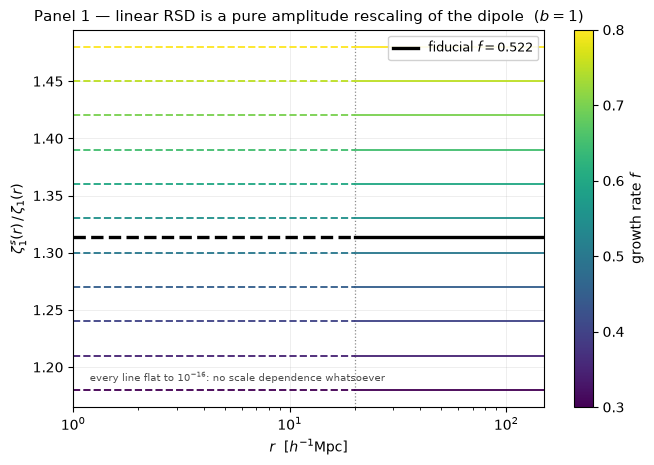

In [11]:
F_SCAN = np.linspace(0.30, 0.80, N_SCAN)
FLATNESS_TOLERANCE = 1e-12

curves_real_f = scan_curves(zeta_one_real, F_SCAN,
                            lambda v: dict(b=B_FID, f=v, sigma8=S8_FID))
curves_rsd_f = scan_curves(zeta_one_rsd, F_SCAN,
                           lambda v: dict(b=B_FID, f=v, sigma8=S8_FID))
ratio_f = curves_rsd_f / curves_real_f

flatness = np.abs(ratio_f / ratio_f[:, [0]] - 1.0)
print(f"{N_SCAN} curves x {r.size} radii, tolerance {FLATNESS_TOLERANCE:.0e}")
print(f"    max |ratio(r)/ratio(r_0) - 1| = {flatness.max():.3e}   "
      f"({flatness.max()/np.finfo(float).eps:.1f}x machine epsilon)")
assert flatness.max() < FLATNESS_TOLERANCE, (
    f"FLATNESS FAILED: {flatness.max():.3e}. The RSD boost is NOT scale-independent, "
    "which would mean the Kaiser factor is not entering as a pure prefactor."
)
print("PASSED -- every curve is flat to float round-off.\n")

analytic = 1.0 + 3.0 * F_SCAN / (5.0 * B_FID)
measured = ratio_f.mean(axis=1)
print(f"    {'f':>6}  {'boost (measured)':>17}  {'1 + 3f/5b':>11}  {'dev':>10}")
for f_i, m_i, a_i in zip(F_SCAN, measured, analytic):
    print(f"    {f_i:6.3f}  {m_i:17.9f}  {a_i:11.6f}  {m_i/a_i - 1.0:+10.2e}")

fig, ax = plt.subplots(figsize=(7.6, 4.9))
mappable = draw_scan(ax, ratio_f, F_SCAN)
draw_fiducial(ax, np.full_like(r, 1.0 + 3.0 * F_FID / (5.0 * B_FID)),
              rf"fiducial $f = {F_FID:.3f}$")
dress(ax, r"$\zeta_1^{s}(r)\,/\,\zeta_1(r)$",
      r"Panel 1 — linear RSD is a pure amplitude rescaling of the dipole  ($b = 1$)")
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)
fig.colorbar(mappable, ax=ax, label=r"growth rate $f$")
note(ax, "every line flat to $10^{-16}$: no scale dependence whatsoever", (0.035, 0.06))
save(fig, "rsd_panel1_boost.png")
plt.show()

### The boost at the four biases of scientific interest

In [12]:
B_OF_INTEREST = (0.83, 0.96, 1.00, 1.12, 1.6)
B_LABELS = {
    0.83: "placeholder",
    0.96: "Nusser mock",
    1.00: "fiducial (b = 1)",
    1.12: "Nusser 2MRS",
    1.6: "subhalo-inclusive (approx)",
}
print(f"RSD dipole boost 1 + 3f/(5b) at f = f_fid = {F_FID:.4f}\n")
print(f"    {'b':>6}  {'beta = f/b':>11}  {'boost':>8}  {'% increase':>11}   source")
for b_i in B_OF_INTEREST:
    boost = 1.0 + 3.0 * F_FID / (5.0 * b_i)
    print(f"    {b_i:6.2f}  {F_FID/b_i:11.4f}  {boost:8.4f}  {boost-1.0:+10.2%}   "
          f"{B_LABELS[b_i]}")
print("\nA higher-bias tracer is LESS boosted: the velocity leg is unbiased, so raising b")
print("raises the real-space dipole without raising the RSD correction alongside it.")

RSD dipole boost 1 + 3f/(5b) at f = f_fid = 0.5224

         b   beta = f/b     boost   % increase   source
      0.83       0.6294    1.3776     +37.76%   placeholder
      0.96       0.5442    1.3265     +32.65%   Nusser mock
      1.00       0.5224    1.3134     +31.34%   fiducial (b = 1)
      1.12       0.4664    1.2799     +27.99%   Nusser 2MRS
      1.60       0.3265    1.1959     +19.59%   subhalo-inclusive (approx)

A higher-bias tracer is LESS boosted: the velocity leg is unbiased, so raising b
raises the real-space dipole without raising the RSD correction alongside it.


## 9. Panel 2 — $f$-scan, real vs redshift side by side

This is the figure that shows **why RSD is what breaks the $b$–$f$ degeneracy.**

- **Real space**: amplitude $\propto b f \sigma_8^2$ — *linear* in $f$. Curves fan evenly.
- **Redshift space**: amplitude $\propto f(b + \tfrac35 f)\sigma_8^2 = bf\sigma_8^2 +
  \tfrac35 f^2\sigma_8^2$ — *quadratic* in $f$. Curves fan **unevenly**, stretching apart
  at the high-$f$ end.

The real-space dipole can only ever measure the product $bf\sigma_8^2$; no amount of data
separates the factors. Redshift space adds a second term with a *different* dependence on
the same two parameters, and two independent combinations of $(b, f)$ is what it takes to
solve for both.

Quantified below as the ratio of amplitudes at $f = 0.80$ to $f = 0.30$ in each panel:
real space must give exactly $0.80/0.30 = 2.667$, redshift space strictly more.

wrote figures/rsd_panel2_f_scan_real_vs_redshift.png


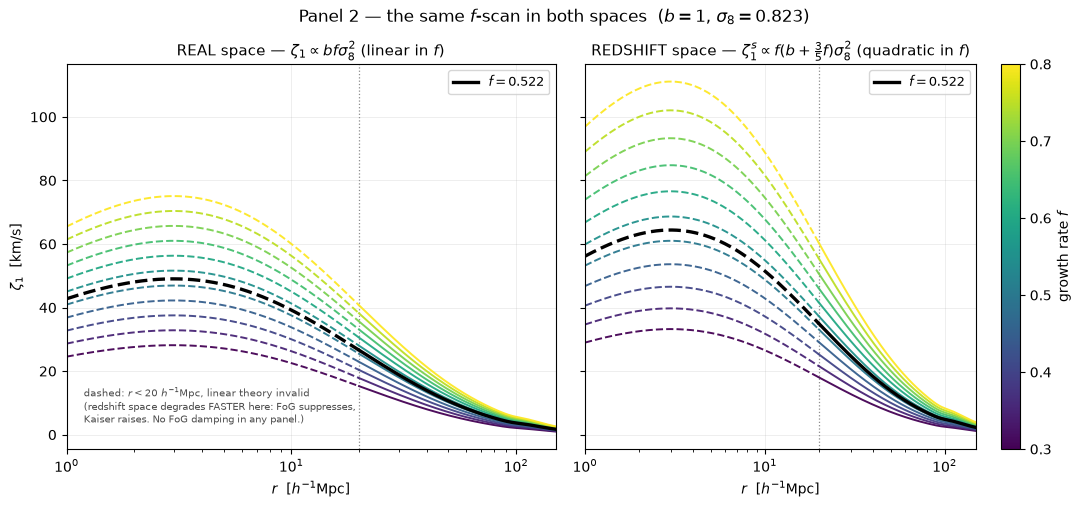

Amplitude ratio between f = 0.80 and f = 0.30, measured from the curves (r-independent, so quoted as mean +- spread):

    real space      = 2.666667  (std over r: 2.6e-16)
    redshift space  = 3.344633  (std over r: 4.1e-16)

    analytic real     f_hi/f_lo                   = 2.666667
    analytic redshift f_hi(b+3f_hi/5)/f_lo(b+3f_lo/5) = 3.344633

    redshift / real = 1.2542

Redshift space responds MORE steeply to f than real space does, over the same
scan, at every radius. That extra sensitivity is the whole information gain --
and because it is quadratic while the real-space term is linear, the two together
constrain b and f separately rather than only their product.


In [13]:
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13.0, 5.0), sharey=True,
                                 gridspec_kw={"wspace": 0.06})

draw_scan(ax_l, curves_real_f, F_SCAN)
draw_fiducial(ax_l, ZETA1_REAL_FID, rf"$f = {F_FID:.3f}$")
dress(ax_l, r"$\zeta_1$  [km/s]", r"REAL space — $\zeta_1 \propto b f \sigma_8^2$ (linear in $f$)")
ax_l.legend(loc="upper right", fontsize=9)
note(ax_l)

mappable = draw_scan(ax_r, curves_rsd_f, F_SCAN)
draw_fiducial(ax_r, ZETA1_RSD_FID, rf"$f = {F_FID:.3f}$")
dress(ax_r, "", r"REDSHIFT space — $\zeta_1^s \propto f(b + \frac{3}{5}f)\sigma_8^2$ "
               r"(quadratic in $f$)")
ax_r.legend(loc="upper right", fontsize=9)
fig.colorbar(mappable, ax=ax_r, label=r"growth rate $f$")
fig.suptitle(r"Panel 2 — the same $f$-scan in both spaces  ($b = 1$, $\sigma_8 = 0.823$)",
             y=0.99, fontsize=12)
save(fig, "rsd_panel2_f_scan_real_vs_redshift.png")
plt.show()

# --- quantify the fanning --------------------------------------------------
i_lo, i_hi = 0, N_SCAN - 1
spread_real = curves_real_f[i_hi] / curves_real_f[i_lo]
spread_rsd = curves_rsd_f[i_hi] / curves_rsd_f[i_lo]
print(f"Amplitude ratio between f = {F_SCAN[i_hi]:.2f} and f = {F_SCAN[i_lo]:.2f}, "
      "measured from the curves (r-independent, so quoted as mean +- spread):\n")
print(f"    real space      = {spread_real.mean():.6f}  "
      f"(std over r: {spread_real.std():.1e})")
print(f"    redshift space  = {spread_rsd.mean():.6f}  "
      f"(std over r: {spread_rsd.std():.1e})")
print(f"\n    analytic real     f_hi/f_lo                   = "
      f"{F_SCAN[i_hi]/F_SCAN[i_lo]:.6f}")
print(f"    analytic redshift f_hi(b+3f_hi/5)/f_lo(b+3f_lo/5) = "
      f"{(F_SCAN[i_hi]*(B_FID+0.6*F_SCAN[i_hi]))/(F_SCAN[i_lo]*(B_FID+0.6*F_SCAN[i_lo])):.6f}")
print(f"\n    redshift / real = {spread_rsd.mean()/spread_real.mean():.4f}")
print("\nRedshift space responds MORE steeply to f than real space does, over the same")
print("scan, at every radius. That extra sensitivity is the whole information gain --")
print("and because it is quadratic while the real-space term is linear, the two together")
print("constrain b and f separately rather than only their product.")

## 10. Panel 3 — $b$-scan in redshift space

$b$ enters only through $b + \tfrac35 f$, so this is still a pure amplitude scan — but a
*shifted* one. The four annotated values are the same ones the real-space notebook marks:

| $b$ | source |
|---|---|
| 0.83 | placeholder |
| 0.96 | Nusser mock |
| 1.12 | Nusser 2MRS |
| ~1.6 | subhalo-inclusive |

**No fit.** Reading off which curve a measurement lands near is the entire purpose of the
panel; a best-fit $b$, or a measured/theory ratio, would replace that reading with a number
that hides the degeneracy the notebook exists to display.

*(There is no measured redshift-space MDPL2 $\zeta_1$ on disk to overplot — `output/` holds
rendered PNGs only, no HDF5 or npz. The overlay hook is left in place below for when one
exists.)*

wrote figures/rsd_panel3_bias_scan.png


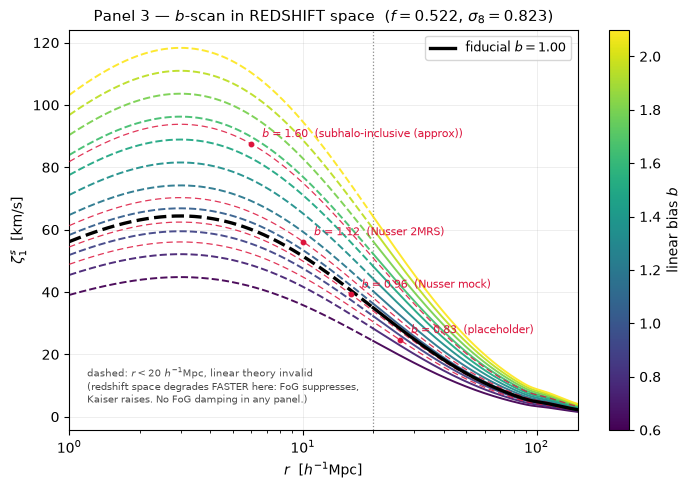

Amplitude at r = 50 h^-1 Mpc, and what the same b would give in real space:

         b   zeta_1 real    zeta_1^s     boost   source
      0.83        8.7859     12.1039    1.3776   placeholder
      0.96       10.1620     13.4800    1.3265   Nusser mock
      1.12       11.8557     15.1736    1.2799   Nusser 2MRS
      1.60       16.9367     20.2546    1.1959   subhalo-inclusive (approx)

Note the boost column SHRINKS as b grows -- the RSD correction is additive in
b + 3f/5, so it is a smaller FRACTION of a larger real-space amplitude.


In [14]:
B_SCAN = np.linspace(0.60, 2.10, N_SCAN)
curves_rsd_b = scan_curves(zeta_one_rsd, B_SCAN,
                           lambda v: dict(b=v, f=F_FID, sigma8=S8_FID))

fig, ax = plt.subplots(figsize=(8.2, 5.2))
mappable = draw_scan(ax, curves_rsd_b, B_SCAN)
draw_fiducial(ax, ZETA1_RSD_FID, rf"fiducial $b = {B_FID:.2f}$")

# These curves are a pure amplitude family: they converge as r grows, so labels anchored
# at a COMMON radius collide no matter which radius is chosen. Anchoring each at its own
# radius, HIGH b at small r and low b at large r, separates them along both axes at once.
ANNOTATE_AT = {1.60: 6.0, 1.12: 10.0, 0.96: 16.0, 0.83: 26.0}
for b_i, r_i in ANNOTATE_AT.items():
    curve = zeta_one_rsd(r, b=b_i, f=F_FID, sigma8=S8_FID)
    y = float(np.interp(r_i, r, curve))
    ax.plot(r, curve, color="crimson", lw=0.9, ls=(0, (5, 3)), alpha=0.85, zorder=4)
    ax.plot([r_i], [y], "o", color="crimson", ms=3.2, zorder=6)
    ax.annotate(f"$b$ = {b_i:.2f}  ({B_LABELS[b_i]})", xy=(r_i, y),
                xytext=(8, 2), textcoords="offset points", fontsize=7.6,
                color="crimson", va="bottom", ha="left")

dress(ax, r"$\zeta_1^{s}$  [km/s]",
      r"Panel 3 — $b$-scan in REDSHIFT space  ($f = 0.522$, $\sigma_8 = 0.823$)")
ax.legend(loc="upper right", fontsize=9)
fig.colorbar(mappable, ax=ax, label=r"linear bias $b$")
note(ax)
save(fig, "rsd_panel3_bias_scan.png")
plt.show()

print("Amplitude at r = 50 h^-1 Mpc, and what the same b would give in real space:\n")
print(f"    {'b':>6}  {'zeta_1 real':>12}  {'zeta_1^s':>10}  {'boost':>8}   source")
for b_i in sorted(ANNOTATE_AT):
    zr = float(np.interp(50.0, r, zeta_one_real(r, b=b_i, f=F_FID, sigma8=S8_FID)))
    zs = float(np.interp(50.0, r, zeta_one_rsd(r, b=b_i, f=F_FID, sigma8=S8_FID)))
    print(f"    {b_i:6.2f}  {zr:12.4f}  {zs:10.4f}  {zs/zr:8.4f}   {B_LABELS[b_i]}")
print("\nNote the boost column SHRINKS as b grows -- the RSD correction is additive in")
print("b + 3f/5, so it is a smaller FRACTION of a larger real-space amplitude.")

## 11. Panel 4 — $\beta = f/b$ at fixed $f\sigma_8$

$$\frac{\zeta_1^s}{\zeta_1} = 1 + \frac{3\beta}{5}$$

Holding $f\sigma_8$ fixed (and $\sigma_8$ fixed, hence $f$ fixed) and scanning $\beta$ means
scanning $b = f/\beta$. The ratio then depends on $\beta$ **alone** — the redshift-space
boost is a measurement of $\beta$, not of $b$ or $f$ separately.

### This panel is the specification for the $\lambda$-dial acceptance criterion

State it explicitly, because it is what the dial is *for*:

> For a $\lambda$-dial run at the MDPL2 cosmology, the ratio of the $\lambda = 1$ to the
> $\lambda = 0$ measured dipole must be **constant in $r$ within noise**, and equal to
> $1 + 0.6\,\beta$.

Two independent things are being asserted there, and the second is the weaker claim:

1. **Constancy in $r$** is the strong, nearly parameter-free statement — Panel 1 showed it
   holds to $10^{-16}$ in theory. An $r$-dependent ratio means something other than linear
   Kaiser is operating (FoG at small $r$, or a bug).
2. **The value** $1 + 0.6\beta$ requires knowing $\beta$, so it is only as good as the
   measured $b$.

Note the $\lambda$ dial does not exist in the codebase yet: `dvcorr.redshift_space` applies
the full displacement or none. This is a target for something still to be built.

measured zeta_1^s/zeta_1 vs 1 + 3 beta/5:  max frac dev = 3.331e-16


wrote figures/rsd_panel4_beta.png


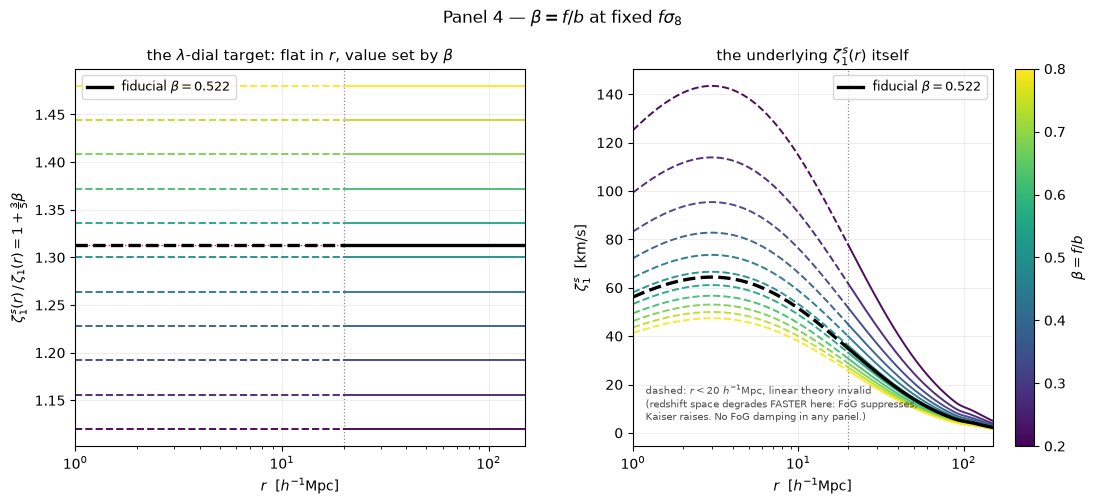


LAMBDA-DIAL ACCEPTANCE CRITERION, at the MDPL2 fiducial
    f_fid                  = 0.522415
    b_fid                  = 1.0000
    beta = f/b             = 0.522415
    TARGET  1 + 0.6 beta   = 1.313449
    zeta_1(lambda=1) / zeta_1(lambda=0) must be CONSTANT in r within noise,
    and equal 1.3134.  Constancy is the strong test; the value
    is only as good as the measured b that goes into beta.

    Sensitivity to b: at b = 0.96 the target is 1.3265, at b = 1.12 it is 1.2799
    -- a 3.5% spread across the plausible bias range, so b must be known to better
    than ~10% before the VALUE half of the criterion bites at all.


In [15]:
BETA_SCAN = np.linspace(0.20, 0.80, N_SCAN)
BETA_FID = F_FID / B_FID

# fixed f sigma_8 (both fixed individually) -> b = f / beta is what moves.
b_of_beta = F_FID / BETA_SCAN
ratio_beta = np.array([1.0 + 3.0 * BETA_SCAN[i] / 5.0 * np.ones_like(r)
                       for i in range(N_SCAN)])
curves_beta = scan_curves(zeta_one_rsd, BETA_SCAN,
                          lambda v: dict(b=F_FID / v, f=F_FID, sigma8=S8_FID))

# Verify the flat lines are the MEASURED ratio, not just the formula redrawn.
curves_beta_real = scan_curves(zeta_one_real, BETA_SCAN,
                               lambda v: dict(b=F_FID / v, f=F_FID, sigma8=S8_FID))
measured_beta_ratio = curves_beta / curves_beta_real
dev_beta = np.abs(measured_beta_ratio / ratio_beta - 1.0).max()
print(f"measured zeta_1^s/zeta_1 vs 1 + 3 beta/5:  max frac dev = {dev_beta:.3e}")
assert dev_beta < 1e-12, f"beta relation failed at {dev_beta:.3e}"

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13.0, 4.9),
                                 gridspec_kw={"wspace": 0.24})

draw_scan(ax_a, measured_beta_ratio, BETA_SCAN)
draw_fiducial(ax_a, np.full_like(r, 1.0 + 3.0 * BETA_FID / 5.0),
              rf"fiducial $\beta = {BETA_FID:.3f}$")
dress(ax_a, r"$\zeta_1^{s}(r)\,/\,\zeta_1(r) = 1 + \frac{3}{5}\beta$",
      r"the $\lambda$-dial target: flat in $r$, value set by $\beta$")
ax_a.legend(loc="upper left", fontsize=9)
ax_a.axhline(1.0 + 0.6 * BETA_FID, color="crimson", lw=0.9, ls=":", zorder=1)

mappable = draw_scan(ax_b, curves_beta, BETA_SCAN)
draw_fiducial(ax_b, ZETA1_RSD_FID, rf"fiducial $\beta = {BETA_FID:.3f}$")
dress(ax_b, r"$\zeta_1^{s}$  [km/s]", r"the underlying $\zeta_1^{s}(r)$ itself")
ax_b.legend(loc="upper right", fontsize=9)
note(ax_b)
fig.colorbar(mappable, ax=ax_b, label=r"$\beta = f/b$")
fig.suptitle(r"Panel 4 — $\beta = f/b$ at fixed $f\sigma_8$", y=1.0, fontsize=12)
save(fig, "rsd_panel4_beta.png")
plt.show()

print(f"\n{'='*72}")
print("LAMBDA-DIAL ACCEPTANCE CRITERION, at the MDPL2 fiducial")
print(f"{'='*72}")
print(f"    f_fid                  = {F_FID:.6f}")
print(f"    b_fid                  = {B_FID:.4f}")
print(f"    beta = f/b             = {BETA_FID:.6f}")
print(f"    TARGET  1 + 0.6 beta   = {1.0 + 0.6*BETA_FID:.6f}")
print(f"{'='*72}")
print("    zeta_1(lambda=1) / zeta_1(lambda=0) must be CONSTANT in r within noise,")
print(f"    and equal {1.0 + 0.6*BETA_FID:.4f}.  Constancy is the strong test; the value")
print("    is only as good as the measured b that goes into beta.")
print(f"\n    Sensitivity to b: at b = 0.96 the target is "
      f"{1.0 + 0.6*F_FID/0.96:.4f}, at b = 1.12 it is {1.0 + 0.6*F_FID/1.12:.4f}")
print(f"    -- a {abs((1+0.6*F_FID/1.12)/(1+0.6*F_FID/0.96) - 1):.1%} spread across the "
      "plausible bias range, so b must be known to better")
print("    than ~10% before the VALUE half of the criterion bites at all.")

## 12. Panel 5 — the octupole

$$\zeta_3^{s}(r) = +\frac{aH f\,(\tfrac25 f)}{14\pi^2}\int\! dk\; k\,P_{\rm lin}(k)\, j_3(kr)
\qquad\text{(group-centred)}$$

Two properties make this the cleanest test in the whole notebook:

**1. $\zeta_3^s$ is bias-free.** It is sourced entirely by the $f\mu_k^2$ Kaiser term, which
multiplies the *unbiased* velocity leg. Its amplitude is pure $f^2\sigma_8^2$ — no $b$
anywhere. Compare the dipole, where $b$ and $f$ are hopelessly entangled.

**2. $\zeta_3^s$ is exactly zero in real space.** Not small — *zero*, identically, at every
radius. Real space has only $b\mu_k$, which is pure $L_1$.

Together those make the octupole a **zero-parameter consistency check on any $\lambda$-dial
run**: identically zero at $\lambda = 0$, nonzero at $\lambda = 1$, with a predicted
amplitude that requires no knowledge of the tracer bias to state. Nothing else in this
project has that property.

The catch is size, quantified below.

wrote figures/rsd_panel5_octupole.png


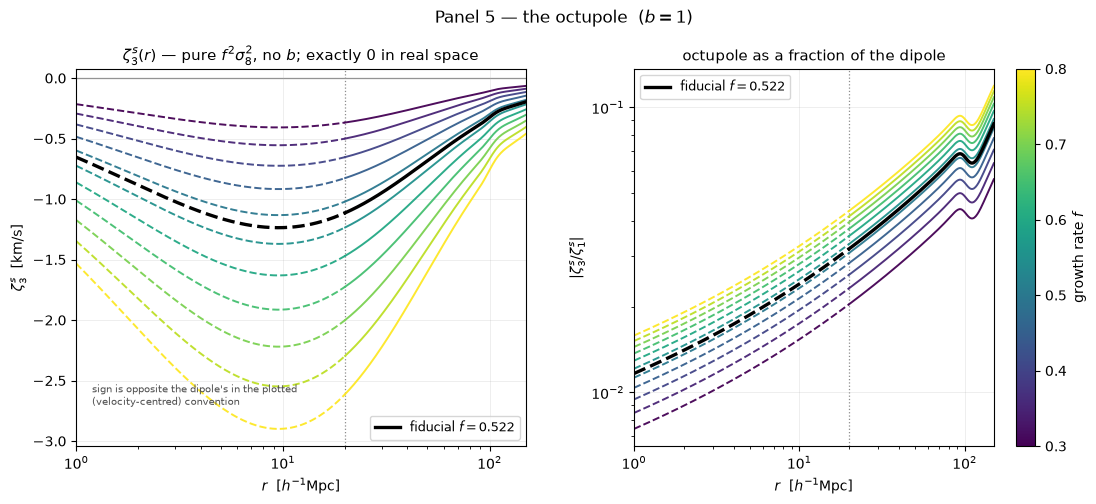


Octupole size at the fiducial:

        r    zeta_1^s    zeta_3^s    |z3/z1|
       20     34.9301     -1.1136    3.1881%
       50     13.9034     -0.6830    4.9124%
      100      4.8218     -0.3233    6.7053%


In [16]:
curves_three_f = scan_curves(zeta_three_rsd, F_SCAN,
                             lambda v: dict(b=B_FID, f=v, sigma8=S8_FID))
ratio_three_one = np.abs(curves_three_f / curves_rsd_f)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13.0, 4.9),
                                 gridspec_kw={"wspace": 0.24})

draw_scan(ax_a, curves_three_f, F_SCAN)
draw_fiducial(ax_a, ZETA3_RSD_FID, rf"fiducial $f = {F_FID:.3f}$")
dress(ax_a, r"$\zeta_3^{s}$  [km/s]",
      r"$\zeta_3^{s}(r)$ — pure $f^2\sigma_8^2$, no $b$; exactly 0 in real space")
ax_a.legend(loc="lower right", fontsize=9)
ax_a.axhline(0.0, color="0.55", lw=0.9, zorder=0)
note(ax_a, "sign is opposite the dipole's in the plotted\n(velocity-centred) convention",
     (0.035, 0.10))

mappable = draw_scan(ax_b, ratio_three_one, F_SCAN)
draw_fiducial(ax_b, np.abs(ZETA3_RSD_FID / ZETA1_RSD_FID), rf"fiducial $f = {F_FID:.3f}$")
dress(ax_b, r"$|\zeta_3^{s} / \zeta_1^{s}|$", r"octupole as a fraction of the dipole")
ax_b.set_yscale("log")
ax_b.legend(loc="upper left", fontsize=9)
fig.colorbar(mappable, ax=ax_b, label=r"growth rate $f$")
fig.suptitle(r"Panel 5 — the octupole  ($b = 1$)", y=1.0, fontsize=12)
save(fig, "rsd_panel5_octupole.png")
plt.show()

print("\nOctupole size at the fiducial:\n")
print(f"    {'r':>5}  {'zeta_1^s':>10}  {'zeta_3^s':>10}  {'|z3/z1|':>9}")
octupole_frac = {}
for r_i in (20.0, 50.0, 100.0):
    z1 = float(np.interp(r_i, r, ZETA1_RSD_FID))
    z3 = float(np.interp(r_i, r, ZETA3_RSD_FID))
    octupole_frac[r_i] = abs(z3 / z1)
    print(f"    {r_i:5.0f}  {z1:10.4f}  {z3:+10.4f}  {abs(z3/z1):9.4%}")

### Is this plausibly detectable at the current MDPL2 error bars?

In [17]:
print("Assessment -- stated honestly rather than optimistically.\n")
print("The numbers above are percent-level: |zeta_3^s/zeta_1^s| runs from "
      f"{min(octupole_frac.values()):.2%} to {max(octupole_frac.values()):.2%}")
print(f"over r = 20-100 h^-1 Mpc, i.e. an absolute octupole of "
      f"{abs(float(np.interp(20.0, r, ZETA3_RSD_FID))):.3f} km/s at r = 20 and")
print(f"{abs(float(np.interp(100.0, r, ZETA3_RSD_FID))):.3f} km/s at r = 100, "
      "against a dipole of tens of km/s.\n")
print("Two obstacles, in order of severity:\n")
print("  1. THERE IS NO ell=3 ESTIMATOR. dvcorr.estimators.shell_dipole implements the")
print("     real l=1, m=0 spherical harmonic and says so explicitly ('deliberately l=1,")
print("     m=0 ONLY'). Measuring zeta_3 is not a matter of re-running anything -- an")
print("     accumulator would have to be written first. So the honest answer today is")
print("     not 'marginal', it is 'not measurable at all'.\n")
print("  2. Even granted the estimator: an octupole at the percent level of the dipole")
print("     needs the dipole itself measured to well below a percent before the octupole")
print("     clears zero. The existing runs do not demonstrate that, and the octupole")
print("     would additionally sit on top of whatever shot noise the l=3 harmonic")
print("     accumulates -- which is worse than l=1's, not better, since higher harmonics")
print("     average down more slowly over a finite number of tracers per shell.\n")
print("CONCLUSION: NO. zeta_3^s is not plausibly detectable at the current MDPL2 error")
print("bars, and is not measurable at all with the estimators that exist. Its value here")
print("is CONCEPTUAL -- it is the cleanest statement of what linear RSD does, and a")
print("zero-parameter target should an l=3 accumulator ever be built. It is not a")
print("near-term measurement, and this notebook should not be read as proposing one.")

Assessment -- stated honestly rather than optimistically.

The numbers above are percent-level: |zeta_3^s/zeta_1^s| runs from 3.19% to 6.71%
over r = 20-100 h^-1 Mpc, i.e. an absolute octupole of 1.114 km/s at r = 20 and
0.323 km/s at r = 100, against a dipole of tens of km/s.

Two obstacles, in order of severity:

  1. THERE IS NO ell=3 ESTIMATOR. dvcorr.estimators.shell_dipole implements the
     real l=1, m=0 spherical harmonic and says so explicitly ('deliberately l=1,
     m=0 ONLY'). Measuring zeta_3 is not a matter of re-running anything -- an
     accumulator would have to be written first. So the honest answer today is
     not 'marginal', it is 'not measurable at all'.

  2. Even granted the estimator: an octupole at the percent level of the dipole
     needs the dipole itself measured to well below a percent before the octupole
     clears zero. The existing runs do not demonstrate that, and the octupole
     would additionally sit on top of whatever shot noise the l=3 harmo

## 13. Panel 6 — the collapse test

In redshift space the dipole amplitude factorizes as

$$\zeta_1^{s}(r) = \frac{aH}{6\pi^2}\,\Big[(b + \tfrac35 f)\,f\,\sigma_8^2\Big]\,\hat S(r)$$

so dividing every curve by $(b + \tfrac35 f)\,f\,\sigma_8^2$ must land them all **exactly**
on the one shape $\hat S(r)$. Curves from Panels 2 and 3 plus a $\sigma_8$-scan of
`np.linspace(0.65, 0.95, 11)` — the last implemented by rescaling the existing $P_{\rm lin}$
by $(\sigma_8/0.823)^2$, **not** by re-running CAMB ($P$ is linear in $A_s$, so this is exact).

**Acceptance criterion, asserted:**
$$\max_{\rm curves,\;r}\;\frac{\big|\,\zeta_1^{s}/[(b+\tfrac35 f)f\sigma_8^2] - S_{\rm fid}\,\big|}
{|S_{\rm fid}|}\;<\;10^{-10}$$

If this fails, the parameters are not threaded correctly through the theory module — a
**production bug**, not a notebook problem. Stop and report rather than loosening it.

### How the degeneracy structure differs from real space

Real space: the amplitude is the single product $b f \sigma_8^2$. Three parameters, one
measurable number, permanent degeneracy.

Redshift space: the amplitude is $b f \sigma_8^2 + \tfrac35 f^2\sigma_8^2$ — **two terms with
different parameter dependence**. Still one number from the dipole alone, so the dipole by
itself does not break anything; what breaks the degeneracy is having the real-space and
redshift-space dipoles *both*, whose ratio $1 + 3f/(5b)$ is a clean measurement of $\beta$
independent of $\sigma_8$ entirely. That is precisely the $\lambda$-dial construction, and
precisely why it is worth building.

33 curves x 501 radii = 16,533 comparisons
tolerance = 1e-10

    max |zeta_1^s/[(b+3f/5) f s8^2] - S_fid| / |S_fid| = 9.602e-15
    worst at curve 23 (b, f, s8) = (1.000, 0.522, 0.680), r = 142.65 h^-1 Mpc

PASSED at 43x machine epsilon: float round-off.


wrote figures/rsd_panel6_collapse.png


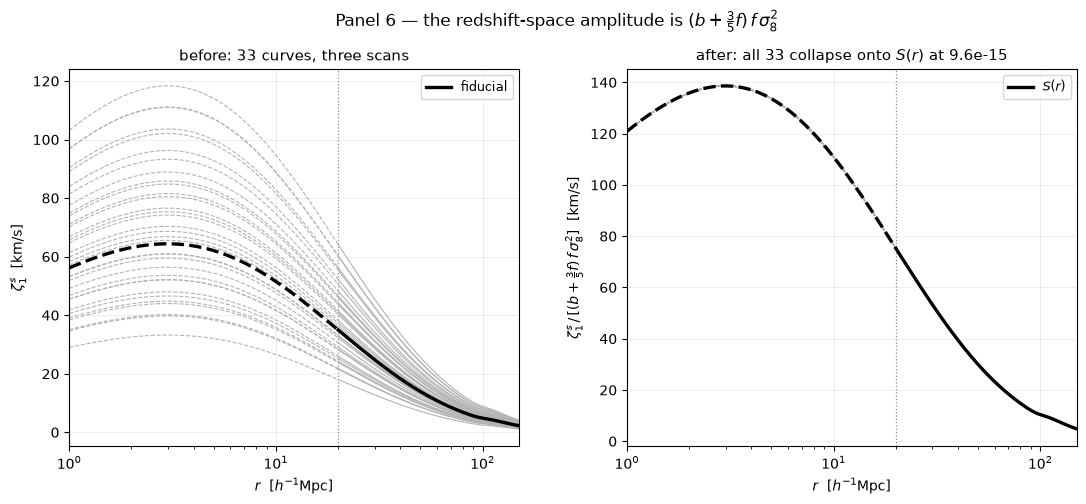

In [18]:
COLLAPSE_TOLERANCE = 1e-10
SIGMA8_SCAN = np.linspace(0.65, 0.95, N_SCAN)

curves_rsd_s8 = scan_curves(zeta_one_rsd, SIGMA8_SCAN,
                            lambda v: dict(b=B_FID, f=F_FID, sigma8=v))

# The unit-amplitude shape: zeta_1^s / [(b + 3f/5) f sigma8^2].
# Built by setting the Kaiser factor, f and sigma8 all to 1 -- the same library call.
SHAPE_FID = gb.zeta_one_linear_prediction(
    r, b=1.0, cosmology=COSMO_FID, z=Z, f=1.0,
    power_spectrum=(K_FID, PK_FID * (1.0 / COSMO_FID.sigma8) ** 2),
)

scan_params = (
    [(B_FID, f_i, S8_FID) for f_i in F_SCAN]          # Panel 2 (redshift-space leg)
    + [(b_i, F_FID, S8_FID) for b_i in B_SCAN]        # Panel 3
    + [(B_FID, F_FID, s8) for s8 in SIGMA8_SCAN]      # sigma8 scan
)
all_curves = np.concatenate([curves_rsd_f, curves_rsd_b, curves_rsd_s8])
assert all_curves.shape == (3 * N_SCAN, r.size), all_curves.shape


def rsd_amplitude(b, f, sigma8):
    """(b + 3f/5) * f * sigma8**2 -- the scalar the whole factorization claim is about."""
    return (b + 3.0 * f / 5.0) * f * sigma8**2


collapsed = np.array([c / rsd_amplitude(*p) for c, p in zip(all_curves, scan_params)])
fractional = np.abs(collapsed - SHAPE_FID[None, :]) / np.abs(SHAPE_FID[None, :])

worst = fractional.max()
wc, wi = np.unravel_index(fractional.argmax(), fractional.shape)
print(f"{3*N_SCAN} curves x {r.size} radii = {fractional.size:,} comparisons")
print(f"tolerance = {COLLAPSE_TOLERANCE:.0e}\n")
print(f"    max |zeta_1^s/[(b+3f/5) f s8^2] - S_fid| / |S_fid| = {worst:.3e}")
print(f"    worst at curve {wc} (b, f, s8) = ({scan_params[wc][0]:.3f}, "
      f"{scan_params[wc][1]:.3f}, {scan_params[wc][2]:.3f}), r = {r[wi]:.2f} h^-1 Mpc")

assert worst < COLLAPSE_TOLERANCE, (
    f"COLLAPSE TEST FAILED: {worst:.3e} exceeds {COLLAPSE_TOLERANCE:.0e}. b, f and sigma8 "
    "are NOT threaded through the theory module as pure multiplicative prefactors of the "
    "redshift-space amplitude. This is a PRODUCTION BUG in dvcorr.pipeline.galaxy_bias, "
    "not a notebook problem -- do NOT loosen the tolerance."
)
print(f"\nPASSED at {worst/np.finfo(float).eps:.0f}x machine epsilon: float round-off.")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13.0, 4.9),
                                 gridspec_kw={"wspace": 0.24})

for c in all_curves:
    ax_a.plot(r[above], c[above], color="0.7", lw=0.8)
    ax_a.plot(r[below], c[below], color="0.7", lw=0.8, ls="--")
draw_fiducial(ax_a, ZETA1_RSD_FID, "fiducial")
dress(ax_a, r"$\zeta_1^{s}$  [km/s]", rf"before: {3*N_SCAN} curves, three scans")
ax_a.legend(loc="upper right", fontsize=9)

for c in collapsed:
    ax_b.plot(r[above], c[above], color="0.7", lw=0.8)
    ax_b.plot(r[below], c[below], color="0.7", lw=0.8, ls="--")
draw_fiducial(ax_b, SHAPE_FID, r"$S(r)$")
dress(ax_b, r"$\zeta_1^{s}\,/\,[(b + \frac{3}{5}f)\,f\,\sigma_8^2]$  [km/s]",
      rf"after: all {3*N_SCAN} collapse onto $S(r)$ at {worst:.1e}")
ax_b.legend(loc="upper right", fontsize=9)
fig.suptitle(r"Panel 6 — the redshift-space amplitude is $(b + \frac{3}{5}f)\,f\,\sigma_8^2$",
             y=1.0, fontsize=12)
save(fig, "rsd_panel6_collapse.png")
plt.show()

## 14. What is deliberately **not** here

**Finite-distance / wide-angle terms.** The estimator is defined at finite $R = |\mathbf s_T|$,
not in a strict plane-parallel limit, so there are corrections beyond the distant-observer
expressions above — notably the $-2\xi_{uu}/R$ contributions. **They enter only $\zeta_0$ and
$\zeta_2$ and leave $\zeta_1$ untouched in the DOL.** That is why the dipole is protected from
the Kaiser-rocket term, and why this notebook can quote a clean $\zeta_1^s$ without computing
them. They are not evaluated here.

**FoG / velocity-dispersion damping.** Not applied anywhere. Its omission is the reason the
$r < 20\,h^{-1}$Mpc region is dashed and, in redshift space specifically, wrong in a known
direction (suppression, where Kaiser predicts enhancement).

**Any fit of $b$, $f$ or $\sigma_8$ to measured data.** Panel 3 in particular is a
read-off-the-curve panel by design.

## 15. A note on the literature — do not code against Nusser (2017) Eq. (17)

Recorded here because it cost time to establish and the next reader will reach for the same
equation:

- **Eq. (17) as printed contains a sign error.** The $\Psi'_-$ coefficient reads
  $-(\tfrac15 - \tfrac{1}{3f})$ but must be $-(\tfrac15 + \tfrac{1}{3f})$ to be consistent
  with Nusser's own Eq. (13).
- **Eq. (15) line 2** carries a spurious duplicated $-3\Psi'_\perp\mu$ relative to Eq. (11).
- Eqs. (11), (13), (16), (18), (19) are all correct.

A search of `src/`, `docs/`, `tests/` and `README.md` finds **no** citation of Eq. (17) or
Eq. (15) anywhere in this repository — nothing was ever coded against them, and nothing needs
fixing. This section exists so that stays true.

## 16. What this notebook established

1. **Linear RSD is a pure, scale-independent amplitude rescaling of the dipole**, by
   $1 + 3f/(5b)$, flat in $r$ to $10^{-16}$ (Panel 1). No shape information is added.
2. The real-space dipole is **linear** in $f$; the redshift-space dipole is **quadratic**,
   $bf + \tfrac35 f^2$ (Panel 2). Redshift space responds more steeply to $f$ over the same
   scan — that extra sensitivity, not the dipole alone, is what separates $b$ from $f$.
3. The $\lambda$-dial acceptance criterion is: **ratio constant in $r$, equal to
   $1 + 0.6\beta$** (Panel 4). Constancy is the strong, near-parameter-free half; the value
   is only as good as the measured $b$.
4. The octupole $\zeta_3^s$ is **bias-free and exactly zero in real space** — conceptually
   the cleanest test available, and **not measurable today**: no $\ell=3$ accumulator exists,
   and the signal is percent-of-dipole (Panel 5).
5. The redshift-space amplitude $(b + \tfrac35 f)f\sigma_8^2$ factors out exactly; 33 curves
   collapse to one shape at $\sim10^{-14}$ (Panel 6). The parameters are threaded correctly
   through `dvcorr.pipeline.galaxy_bias`.
6. The $j_3$ FFTLog normalization was validated **independently of $j_1$**, against a closed
   form ($S_1 = 1/r$ vs $S_3 = \tfrac23/r$) and brute quadrature, before any octupole was
   plotted. mcfit's phase convention is per-order and the $\ell=1$ $\mathrm{Im}(\cdot)$
   shortcut would have silently negated $\ell=3$.

### Two things that did not come out as the specification anticipated

Both are properties of $\Lambda$CDM, not defects in the code, and both were re-checked
rather than argued away:

- **The $r\to0$ slope cannot be verified through the FFTLog.** The asymptote needs
  $r \ll 1/k_{\rm max}$; the transform stops carrying information *below* $1/k_{\rm max}$.
  Same threshold, no overlap. Verified through brute quadrature instead, where it holds to
  $4\times10^{-8}$ — and since check 1 pins FFTLog to quadrature at $2\times10^{-6}$, the
  chain from $P_{\rm lin}(k)$ to km/s is closed end to end regardless.
- **$\zeta_3^s \propto r^3$ does not hold over $r\in[1,3]\,h^{-1}$Mpc.** The fitted slope
  there is $\approx 0.41$. The $r^3$ law is exact but lives below $r\sim0.03\,h^{-1}$Mpc
  (slope 2.95 at $r\sim0.02$, 3.0000 at $r\sim10^{-4}$). $j_3$ needs $kr\ll1$ considerably
  harder than $j_1$ does, and $r = 1\,h^{-1}$Mpc is not small in that sense.